# 03 · Redes neuronales

In [1]:
#%pip install tensorflow
#%pip install scikeras

In [2]:
# Librerías base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Funciones compartidas del proyecto (métricas, gráficas, rutas) -> archivo churn_utils.py
from churn_utils import *

pd.options.display.max_columns = None
plt.rcParams["figure.dpi"] = 100

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # menos mensajes de TensorFlow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, classification_report
import time

tf.keras.utils.set_random_seed(SEMILLA)   # reproducibilidad
print("TensorFlow", tf.__version__)

I0000 00:00:1794702054.756399     447 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794702071.275294     447 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


In [3]:
# Cargar los datos ya preparados por el notebook 00 (mismo train/test para TODOS los modelos)
datos = cargar_datos_modelo()
X_train, X_test = datos["X_train"], datos["X_test"]
y_train, y_test = datos["y_train"], datos["y_test"]

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)
print("Tasa de fuga en train: %.2f%% | en test: %.2f%%" % (100 * y_train.mean(), 100 * y_test.mean()))

Entrenamiento: (8101, 33) | Test: (2026, 33)
Tasa de fuga en train: 16.07% | en test: 16.04%


## 1. Red de clase (128 → 64, Dropout) con scikeras

In [4]:
# Definir la arquitectura y las métricas de optimización de la red neuronal.
# scikeras le pasa a la función el diccionario 'meta' con el número de variables de entrada (n_features_in_),
# así la red se construye sola con el tamaño correcto.
def create_model(meta, n1=128, n2=64, dropout=0.3, learning_rate=0.001):
    n_entrada = meta["n_features_in_"]
    model = keras.Sequential([
        layers.Input(shape=(n_entrada,)),
        layers.Dense(n1, activation="relu", name="oculta-1"),
        layers.Dropout(dropout),
        layers.Dense(n2, activation="relu", name="oculta-2"),
        layers.Dropout(dropout * 2 / 3),
        layers.Dense(1, activation="sigmoid", name="salida"),
    ])
    adam = keras.optimizers.Adam(learning_rate=learning_rate)   # método de optimización
    model.compile(loss="binary_crossentropy", optimizer=adam, metrics=[keras.metrics.AUC(name="auc")])
    return model

nn_estimators = []
nn_estimators.append(("standardize", StandardScaler()))   # Estandarizar los datos de entrada
nn_estimators.append(("mlp", KerasClassifier(model=create_model, epochs=30, batch_size=128,
                                             validation_split=0.2, verbose=0, random_state=SEMILLA)))
Clasificador_RN = Pipeline(nn_estimators, verbose=False)

inicio = time.time()
Clasificador_RN.fit(X_train, y_train)
print("Tiempo de entrenamiento: %.1f s" % (time.time() - inicio))
Clasificador_RN.named_steps["mlp"].model_.summary()

Tiempo de entrenamiento: 7.7 s


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta-1 (Dense)                │ (None, 128)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta-2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,021 (148.52 KB)

 Trainable params: 12,673 (49.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 25,348 (99.02 KB)

Métricas del modelo: Red neuronal (clase, 30 épocas)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1658  113]
 [  43  212]]
 Accuracy        : 0.9230
 Sensibilidad    : 0.6523
 Especificidad   : 0.9747
 Precision (VPP) : 0.8314
 VPN             : 0.9362
 F1              : 0.7310
 AUC             : 0.9572
 PR-AUC          : 0.8367


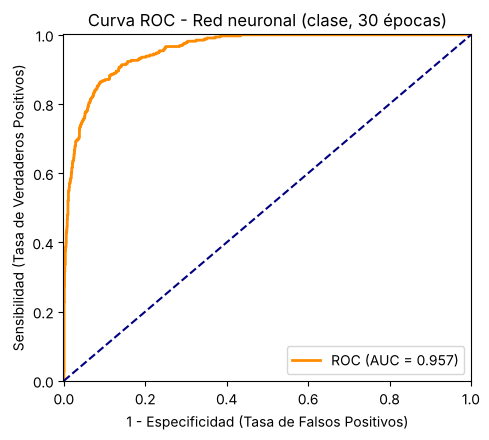

In [5]:
# Predecir datos de test
y_pred_prob = Clasificador_RN.predict_proba(X_test)[:, 1]
metricas_rn_base = evaluar_modelo("Red neuronal (clase, 30 épocas)", y_test, y_pred_prob)

## 2. Curvas de aprendizaje

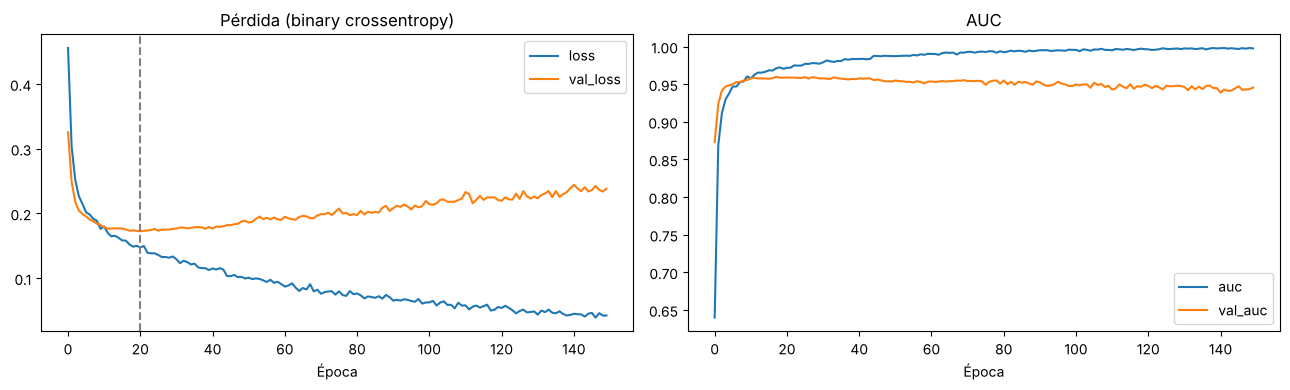

Época con menor pérdida de validación: 21


In [6]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEMILLA)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_val_s = scaler.transform(X_tr), scaler.transform(X_val)

tf.keras.utils.set_random_seed(SEMILLA)
red = create_model({"n_features_in_": X_tr_s.shape[1]})
historia = red.fit(X_tr_s, y_tr, validation_data=(X_val_s, y_val), epochs=150, batch_size=128, verbose=0)

h = pd.DataFrame(historia.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
h[["loss", "val_loss"]].plot(ax=axes[0], title="Pérdida (binary crossentropy)"); axes[0].set_xlabel("Época")
h[["auc", "val_auc"]].plot(ax=axes[1], title="AUC"); axes[1].set_xlabel("Época")
axes[0].axvline(h["val_loss"].idxmin(), color="gray", ls="--")
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/rn_curvas_aprendizaje.png", bbox_inches="tight"); plt.show()
print("Época con menor pérdida de validación:", h["val_loss"].idxmin() + 1)

* La validación empeora después de ~20 épocas → se usa EarlyStopping.

## 3. GridSearchCV con scikeras

In [7]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
pesos_clase = {0: pesos[0], 1: pesos[1]}
print("Pesos por clase (balanced):", {k: round(v, 2) for k, v in pesos_clase.items()})

pipe_rn = Pipeline([("standardize", StandardScaler()),
                    ("mlp", KerasClassifier(model=create_model, epochs=200, batch_size=128, validation_split=0.15,
                                            callbacks=[early_stop], verbose=0, random_state=SEMILLA))])

param_grid = {"mlp__model__n1": [64, 128],
              "mlp__model__n2": [32],
              "mlp__model__dropout": [0.2, 0.4],
              "mlp__model__learning_rate": [0.001, 0.003],
              "mlp__class_weight": [None, pesos_clase]}

# Scorer propio de AUC: el scorer "roc_auc" de sklearn no reconoce bien las probabilidades de scikeras en
# algunas versiones (devuelve NaN). Con esta función le pasamos explícitamente la probabilidad de la clase 1.
def auc_scorer(estimador, X, y):
    return roc_auc_score(y, estimador.predict_proba(X)[:, 1])

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
inicio = time.time()
grid_rn = GridSearchCV(pipe_rn, param_grid, cv=cv3, scoring=auc_scorer, n_jobs=1, verbose=1).fit(X_train, y_train)
print("Tiempo: %.1f s" % (time.time() - inicio))
print("Mejores hiperparámetros:", grid_rn.best_params_)
print("Mejor AUC validación cruzada: %.4f" % grid_rn.best_score_)

Pesos por clase (balanced): {0: np.float64(0.6), 1: np.float64(3.11)}
Fitting 3 folds for each of 16 candidates, totalling 48 fits


Tiempo: 380.8 s
Mejores hiperparámetros: {'mlp__class_weight': None, 'mlp__model__dropout': 0.4, 'mlp__model__learning_rate': 0.003, 'mlp__model__n1': 128, 'mlp__model__n2': 32}
Mejor AUC validación cruzada: 0.9601


In [8]:
res = pd.DataFrame(grid_rn.cv_results_)
res["params_txt"] = res["params"].apply(lambda p: f"n1={p['mlp__model__n1']}, drop={p['mlp__model__dropout']}, "
                                                   f"lr={p['mlp__model__learning_rate']}, pesos={'sí' if p['mlp__class_weight'] else 'no'}")
res[["params_txt", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").round(4)

,params_txt,mean_test_score,std_test_score,rank_test_score
7,"n1=128, drop=0.4, lr=0.003, pesos=no",0.9601,0.0058,1
5,"n1=128, drop=0.4, lr=0.001, pesos=no",0.9601,0.0035,2
15,"n1=128, drop=0.4, lr=0.003, pesos=sí",0.9598,0.0037,3
3,"n1=128, drop=0.2, lr=0.003, pesos=no",0.9595,0.0031,4
1,"n1=128, drop=0.2, lr=0.001, pesos=no",0.9591,0.0033,5
13,"n1=128, drop=0.4, lr=0.001, pesos=sí",0.9581,0.0033,6
6,"n1=64, drop=0.4, lr=0.003, pesos=no",0.9579,0.0021,7
9,"n1=128, drop=0.2, lr=0.001, pesos=sí",0.9578,0.0020,8
11,"n1=128, drop=0.2, lr=0.003, pesos=sí",0.9571,0.0026,9
0,"n1=64, drop=0.2, lr=0.001, pesos=no",0.9562,0.0025,10


Métricas del modelo: Red Neuronal (ajustada)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1645   92]
 [  56  233]]
 Accuracy        : 0.9269
 Sensibilidad    : 0.7169
 Especificidad   : 0.9671
 Precision (VPP) : 0.8062
 VPN             : 0.9470
 F1              : 0.7590
 AUC             : 0.9653
 PR-AUC          : 0.8569


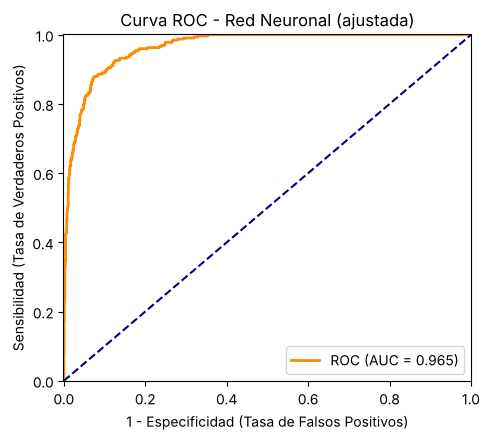

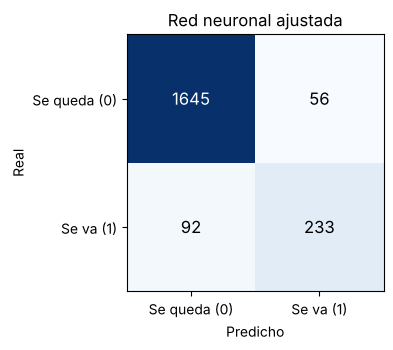

              precision    recall  f1-score   support

    Se queda       0.95      0.97      0.96      1701
       Se va       0.81      0.72      0.76       325

    accuracy                           0.93      2026
   macro avg       0.88      0.84      0.86      2026
weighted avg       0.92      0.93      0.93      2026

Resultados guardados en: resultados/Red_Neuronal_Keras.pkl


In [9]:
# Evaluar la mejor red en TEST
y_pred_prob_rn = grid_rn.predict_proba(X_test)[:, 1]
metricas_rn = evaluar_modelo("Red Neuronal (ajustada)", y_test, y_pred_prob_rn)
plot_confusion(y_test, np.where(y_pred_prob_rn > 0.5, 1, 0), "Red neuronal ajustada")
print(classification_report(y_test, np.where(y_pred_prob_rn > 0.5, 1, 0), target_names=["Se queda", "Se va"]))
guardar_resultados("Red Neuronal Keras", y_test, y_pred_prob_rn, metricas_rn,
                   {k: (v if not isinstance(v, dict) else "balanced") for k, v in grid_rn.best_params_.items()})

## 4. MLPClassifier de sklearn

In [10]:
grid_mlp = GridSearchCV(
    Pipeline([("scaler", StandardScaler()),
              ("mlp", MLPClassifier(max_iter=500, early_stopping=True, n_iter_no_change=20, random_state=SEMILLA))]),
    param_grid={"mlp__hidden_layer_sizes": [(64,), (64, 32), (128, 64)], "mlp__alpha": [1e-4, 1e-2]},
    cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print("Mejores hiperparámetros MLP:", grid_mlp.best_params_, "| AUC CV: %.4f" % grid_mlp.best_score_)

y_pred_prob_mlp = grid_mlp.predict_proba(X_test)[:, 1]
metricas_mlp = evaluar_modelo("MLP sklearn", y_test, y_pred_prob_mlp, graficar=False)
guardar_resultados("MLP sklearn", y_test, y_pred_prob_mlp, metricas_mlp, grid_mlp.best_params_)

Mejores hiperparámetros MLP: {'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (128, 64)} | AUC CV: 0.9574
Métricas del modelo: MLP sklearn  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1626   86]
 [  75  239]]
 Accuracy        : 0.9205
 Sensibilidad    : 0.7354
 Especificidad   : 0.9559
 Precision (VPP) : 0.7611
 VPN             : 0.9498
 F1              : 0.7480
 AUC             : 0.9511
 PR-AUC          : 0.8356
Resultados guardados en: resultados/MLP_sklearn.pkl


## Resumen redes
* Red de clase: AUC 0,957. Red ajustada: AUC 0,965.
* Queda por debajo del Gradient Boosting: los árboles capturan mejor los umbrales de estas variables.
* Caja negra y con variación entre corridas.